# Árvores de Decisão

Dois exemplos com Python + scikit-learn:

| | Pergunta | Mede a qualidade do nó com | Escolhe a pergunta pela |
|---|---|---|---|
| **Parte 1 — Classificação** | A pessoa vai presencial? (Sim/Não) | Entropia | Ganho de Informação |
| **Parte 2 — Regressão** | Quantos litros de cerveja São Paulo consome no dia? | MSE | Redução do MSE |

Paleta em todos os gráficos: **Preto, Branco, Laranja e Azul Escuro**.

# Parte 1 — Classificação: vai presencial?

**Exemplo 1** — Árvore de Decisão com Python + scikit-learn, usando **Entropia e Ganho de Informação**.

Regras do modelo híbrido sem escala:
- **Cientista de dados** → vai presencial **uma vez por semana**, preferencialmente na **segunda-feira**.
- **Demais pessoas da área** → vão **dois dias**: **segunda** e **terça** (dia preferencial).
- Ou seja, na prática **segunda-feira é presencial para todos**.

Cada linha é **uma pessoa em um dia**. Variáveis (Sim = 1, Não = 0):

| variável | pergunta |
|---|---|
| `cientista_dados` | A pessoa é cientista de dados? |
| `e_segunda` | O dia é segunda-feira? |
| `e_terca` | O dia é terça-feira? |
| **`presencial`** (alvo) | **A pessoa vai presencial?** |

Paleta: **Preto, Branco, Laranja (Presencial = Sim) e Azul Escuro (Presencial = Não)**.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text

PRETO, BRANCO, LARANJA, AZUL_ESCURO = "#000000", "#FFFFFF", "#F28C28", "#0B2545"
COR_CLASSE = {"Sim": LARANJA, "Não": AZUL_ESCURO}

plt.rcParams.update({
    "figure.facecolor": BRANCO, "axes.facecolor": BRANCO,
    "axes.edgecolor": PRETO, "axes.labelcolor": PRETO, "text.color": PRETO,
    "xtick.color": PRETO, "ytick.color": PRETO, "font.size": 11,
})

## 1. Dados

In [2]:
df = pd.DataFrame({
    "cientista_dados": [1, 1, 1, 0, 0, 0],
    "e_segunda":       [1, 0, 0, 1, 0, 0],
    "e_terca":         [0, 1, 0, 0, 1, 0],
})

def regra(linha):
    if linha["e_segunda"] == 1:  # segunda é presencial para todos
        return "Sim"
    if linha["e_terca"] == 1 and linha["cientista_dados"] == 0:  # demais também vão na terça
        return "Sim"
    return "Não"

df["presencial"] = df.apply(regra, axis=1)
FEATURES = ["e_segunda", "cientista_dados", "e_terca"]
df

,cientista_dados,e_segunda,e_terca,presencial
0,1,1,0,Sim
1,1,0,1,Não
2,1,0,0,Não
3,0,1,0,Sim
4,0,0,1,Sim
5,0,0,0,Não


## 2. Intuição: traçando "retas" no quadrante
Eixo X = **É cientista de dados?** · Eixo Y = **É segunda?**

Nos dias que não são segunda, o ponto de cima é a **terça** e o de baixo é **outro dia**.

A árvore procura retas (perguntas Sim/Não) que deixem cada região com uma só cor:
1. **É segunda?** → a metade de cima fica toda laranja.
2. **É cientista?** → embaixo à direita fica todo azul.
3. **É terça?** → resolve o único quadrante que ainda estava misturado.

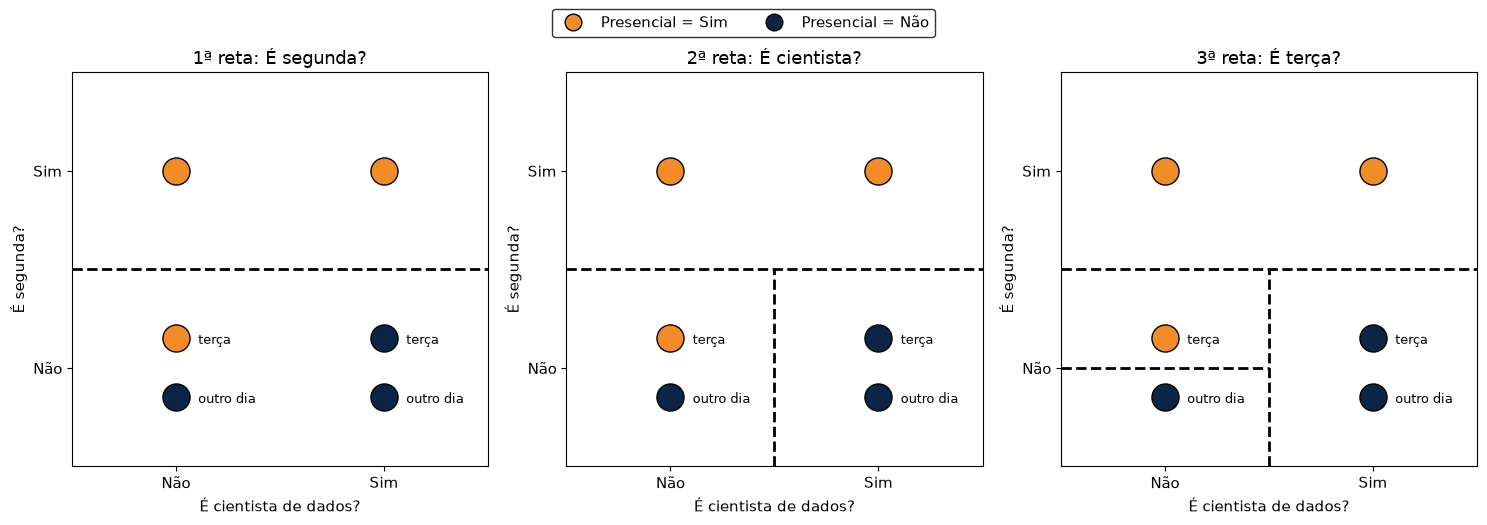

In [3]:
def posicao(linha):
    x = linha["cientista_dados"]
    y = linha["e_segunda"]
    if y == 0:
        y += 0.15 if linha["e_terca"] else -0.15
    return x, y


def quadrante(ax, passo, titulo):
    for _, linha in df.iterrows():
        x, y = posicao(linha)
        ax.scatter(x, y, s=380, c=COR_CLASSE[linha["presencial"]], edgecolors=PRETO, zorder=3)
        if linha["e_segunda"] == 0:
            ax.annotate("terça" if linha["e_terca"] else "outro dia", (x, y),
                        xytext=(16, -4), textcoords="offset points", fontsize=9)
    if passo >= 1:
        ax.plot([-0.5, 1.5], [0.5, 0.5], color=PRETO, lw=2, ls="--")
    if passo >= 2:
        ax.plot([0.5, 0.5], [-0.5, 0.5], color=PRETO, lw=2, ls="--")
    if passo >= 3:
        ax.plot([-0.5, 0.5], [0, 0], color=PRETO, lw=2, ls="--")
    ax.set_xticks([0, 1], ["Não", "Sim"]); ax.set_yticks([0, 1], ["Não", "Sim"])
    ax.set_xlim(-0.5, 1.5); ax.set_ylim(-0.5, 1.5)
    ax.set_xlabel("É cientista de dados?"); ax.set_ylabel("É segunda?")
    ax.set_title(titulo)


fig, axes = plt.subplots(1, 3, figsize=(15, 5))
for ax, passo, titulo in zip(axes, [1, 2, 3], ["1ª reta: É segunda?", "2ª reta: É cientista?", "3ª reta: É terça?"]):
    quadrante(ax, passo, titulo)

handles = [plt.Line2D([], [], marker="o", ls="", markersize=12, markerfacecolor=c,
                      markeredgecolor=PRETO, label=f"Presencial = {k}") for k, c in COR_CLASSE.items()]
fig.legend(handles=handles, loc="upper center", ncol=2, edgecolor=PRETO, bbox_to_anchor=(0.5, 1.06))
plt.tight_layout(); plt.show()

## 3. Entropia e Ganho de Informação
Por que a árvore pergunta **"É segunda?"** primeiro? Ela mede a **mistura** de cada grupo com a **Entropia**
e escolhe a pergunta que mais reduz essa mistura — o **Ganho de Informação**.

### A curva da entropia
*(seção recolhível: clique na seta ao lado do título para esconder ou mostrar)*
Com duas classes, a entropia depende só da proporção $p$ de **Sim** no grupo:

$$H(p) = -p \log_2 p - (1 - p) \log_2 (1 - p)$$

Vale **0** nas pontas (grupo puro) e chega ao máximo, **1**, em $p = 0{,}5$ (metade/metade).

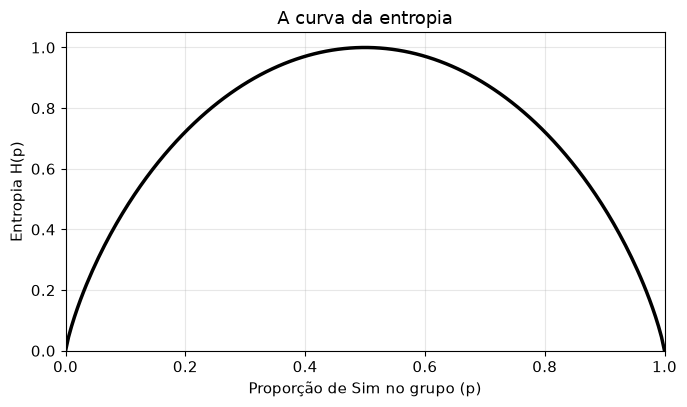

In [4]:
p = np.linspace(0, 1, 201)
log = lambda x, ok: np.log2(x, where=ok, out=np.zeros_like(x))  # log2(0) não existe; nas pontas H = 0

fig, ax = plt.subplots(figsize=(7, 4.2))
ax.plot(p, -(p * log(p, p > 0) + (1 - p) * log(1 - p, p < 1)), color=PRETO, lw=2.5)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.05)
ax.set_xlabel("Proporção de Sim no grupo (p)"); ax.set_ylabel("Entropia H(p)")
ax.set_title("A curva da entropia")
ax.grid(alpha=0.3)
plt.tight_layout(); plt.show()

### Entropia e Ganho: as fórmulas
$$H(S) = -\sum_i p_i \log_2 p_i$$

- $H = 0$ → grupo puro (todos Sim ou todos Não)
- $H = 1$ → metade Sim, metade Não (mistura máxima)

$$IG(S, A) = H(S) - \sum_{v \in \{Sim,\,Não\}} \frac{|S_v|}{|S|}\, H(S_v)$$

### Exemplo passo a passo

**Parte A — Entropia da raiz**

1. **Contamos as classes:** 6 casos → **3 Sim** e **3 Não**.
2. **Proporções:** $p(Sim) = 3/6 = 0{,}5$ e $p(Não) = 3/6 = 0{,}5$
3. **Log₂ de cada proporção:** "2 elevado a quanto dá 0,5?" → $\log_2(0{,}5) = -1$.
   O log de um número menor que 1 é sempre negativo — por isso a fórmula tem um sinal de menos na frente.
4. **Proporção × log:** $0{,}5 \times (-1) = -0{,}5$ para cada classe.
5. **Somamos e trocamos o sinal:** $H(raiz) = -(-0{,}5 - 0{,}5) = 1$ → **mistura máxima**.

**Parte B — Ganho de "É segunda?"**

6. **Separamos os casos:** ramo Sim → 2 casos (2 Sim, 0 Não) · ramo Não → 4 casos (1 Sim, 3 Não).
7. **Entropia do ramo Sim:** grupo puro → $p(Sim) = 1$, $\log_2(1) = 0$ → $H = 0$.
8. **Entropia do ramo Não — proporções e logs:**
   $p(Sim) = 1/4 = 0{,}25 \Rightarrow \log_2(0{,}25) = -2$ · $p(Não) = 3/4 = 0{,}75 \Rightarrow \log_2(0{,}75) \approx -0{,}415$
9. **Produto e soma:** $0{,}25 \times (-2) = -0{,}500$ · $0{,}75 \times (-0{,}415) = -0{,}311$ → $H = -(-0{,}500 - 0{,}311) = 0{,}811$
10. **Média ponderada dos ramos** (2 de 6 casos no ramo Sim, 4 de 6 no ramo Não):
    $H(filhos) = \tfrac{2}{6} \times 0 + \tfrac{4}{6} \times 0{,}811 = 0{,}541$
11. **Ganho:** $IG = H(raiz) - H(filhos) = 1 - 0{,}541 = 0{,}459$

A mesma conta em Python, mostrando cada passo:

In [5]:
from math import log2

# Parte A — raiz
sim, nao = 3, 3
total = sim + nao
p_sim, p_nao = sim / total, nao / total
print(f"1. Contagem: {sim} Sim, {nao} Não, total {total}")
print(f"2. Proporções: p(Sim) = {p_sim}, p(Não) = {p_nao}")
print(f"3. Logs: log2({p_sim}) = {log2(p_sim)}, log2({p_nao}) = {log2(p_nao)}")
print(f"4. Produtos: {p_sim * log2(p_sim)} e {p_nao * log2(p_nao)}")
h_raiz = -(p_sim * log2(p_sim) + p_nao * log2(p_nao))
print(f"5. H(raiz) = {h_raiz:.3f}")

# Parte B — ganho de "É segunda?"
print("\n6. Ramo Sim: 2 Sim / 0 Não  |  Ramo Não: 1 Sim / 3 Não")
h_ramo_sim = -(1 * log2(1))
print(f"7. H(ramo Sim) = {abs(h_ramo_sim):.3f}  (grupo puro)")
p1, p2 = 1 / 4, 3 / 4
print(f"8. p = {p1} → log2 = {log2(p1):.3f}  |  p = {p2} → log2 = {log2(p2):.3f}")
h_ramo_nao = -(p1 * log2(p1) + p2 * log2(p2))
print(f"9. {p1 * log2(p1):.3f} + ({p2 * log2(p2):.3f}) → H(ramo Não) = {h_ramo_nao:.3f}")
h_filhos = 2 / 6 * 0 + 4 / 6 * h_ramo_nao
print(f"10. H(filhos) = 2/6 × 0 + 4/6 × {h_ramo_nao:.3f} = {h_filhos:.3f}")
print(f"11. Ganho = {h_raiz:.3f} − {h_filhos:.3f} = {h_raiz - h_filhos:.3f}")

1. Contagem: 3 Sim, 3 Não, total 6
2. Proporções: p(Sim) = 0.5, p(Não) = 0.5
3. Logs: log2(0.5) = -1.0, log2(0.5) = -1.0
4. Produtos: -0.5 e -0.5
5. H(raiz) = 1.000

6. Ramo Sim: 2 Sim / 0 Não  |  Ramo Não: 1 Sim / 3 Não
7. H(ramo Sim) = 0.000  (grupo puro)
8. p = 0.25 → log2 = -2.000  |  p = 0.75 → log2 = -0.415
9. -0.500 + (-0.311) → H(ramo Não) = 0.811
10. H(filhos) = 2/6 × 0 + 4/6 × 0.811 = 0.541
11. Ganho = 1.000 − 0.541 = 0.459


### Repetindo para todas as perguntas, nível a nível

In [6]:
def entropia(y):
    p = y.value_counts(normalize=True)
    return abs(float(-(p * np.log2(p)).sum()))  # abs evita exibir -0.0


def tabela_ganhos(dados, features, alvo="presencial"):
    # Para cada variável: composição dos ramos, entropia e ganho
    linhas = []
    for f in features:
        sim, nao = dados[dados[f] == 1], dados[dados[f] == 0]
        h_filhos = len(sim) / len(dados) * entropia(sim[alvo]) + len(nao) / len(dados) * entropia(nao[alvo])
        linhas.append({
            "variável": f,
            "ramo Sim": f"{(sim[alvo] == 'Sim').sum()} Sim / {(sim[alvo] == 'Não').sum()} Não",
            "H ramo Sim": round(entropia(sim[alvo]), 3),
            "ramo Não": f"{(nao[alvo] == 'Sim').sum()} Sim / {(nao[alvo] == 'Não').sum()} Não",
            "H ramo Não": round(entropia(nao[alvo]), 3),
            "ganho": round(entropia(dados[alvo]) - h_filhos, 3),
        })
    return pd.DataFrame(linhas).sort_values("ganho", ascending=False)

### Nível 1 — raiz

In [7]:
print(f"Entropia da raiz: {entropia(df['presencial']):.3f}")
tabela_ganhos(df, FEATURES)

Entropia da raiz: 1.000


,variável,ramo Sim,H ramo Sim,ramo Não,H ramo Não,ganho
0,e_segunda,2 Sim / 0 Não,0.000,1 Sim / 3 Não,0.811,0.459
1,cientista_dados,1 Sim / 2 Não,0.918,2 Sim / 1 Não,0.918,0.082
2,e_terca,1 Sim / 1 Não,1.000,2 Sim / 2 Não,1.000,0.000


`e_segunda` vence com folga. Repare em `e_terca`: ganho **zero** na raiz — sozinha ela não ajuda (mas vai ser decisiva depois).

### Nível 2 — ramo "não é segunda"

In [8]:
nivel2 = df[df["e_segunda"] == 0]
print(f"Entropia do nó: {entropia(nivel2['presencial']):.3f}")
tabela_ganhos(nivel2, ["cientista_dados", "e_terca"])

Entropia do nó: 0.811


,variável,ramo Sim,H ramo Sim,ramo Não,H ramo Não,ganho
0,cientista_dados,0 Sim / 2 Não,0.0,1 Sim / 1 Não,1.0,0.311
1,e_terca,1 Sim / 1 Não,1.0,0 Sim / 2 Não,0.0,0.311


**Empate!** `cientista_dados` e `e_terca` têm o mesmo ganho (0,311). Empates acontecem: qualquer uma das duas leva a uma
árvore pura no final. Escolhemos `cientista_dados` (mesma ordem do quadrante). O scikit-learn desempata de forma
aleatória, por isso fixamos o `random_state`.

### Nível 3 — ramo "não é segunda" e "não é cientista"

In [9]:
nivel3 = nivel2[nivel2["cientista_dados"] == 0]
print(f"Entropia do nó: {entropia(nivel3['presencial']):.3f}")
tabela_ganhos(nivel3, ["e_terca"])

Entropia do nó: 1.000


,variável,ramo Sim,H ramo Sim,ramo Não,H ramo Não,ganho
0,e_terca,1 Sim / 0 Não,0.0,0 Sim / 1 Não,0.0,1.0


Ganho = 1: a pergunta "É terça?" elimina toda a mistura que restava. Todas as folhas ficam puras.

## 4. A árvore com scikit-learn
`criterion="entropy"` faz o sklearn usar exatamente esses cálculos.

|--- e_segunda <= 0.50
|   |--- cientista_dados <= 0.50
|   |   |--- e_terca <= 0.50
|   |   |   |--- class: Não
|   |   |--- e_terca >  0.50
|   |   |   |--- class: Sim
|   |--- cientista_dados >  0.50
|   |   |--- class: Não
|--- e_segunda >  0.50
|   |--- class: Sim



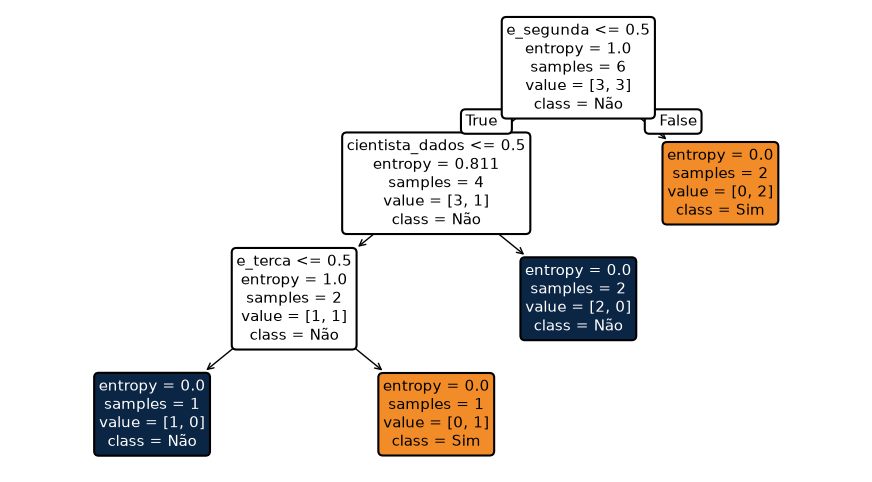

In [10]:
def desenhar_arvore(modelo, features, tamanho=(11, 6)):
    fig, ax = plt.subplots(figsize=tamanho)
    nos = plot_tree(modelo, feature_names=features, class_names=list(modelo.classes_),
                    filled=True, rounded=True, impurity=True, fontsize=11, ax=ax)

    # Aplica a paleta: folhas laranja/azul escuro, nós internos brancos
    for texto in nos:
        conteudo = texto.get_text()
        if "class = " in conteudo and "<=" not in conteudo:
            cor = COR_CLASSE[conteudo.split("class = ")[1].strip()]
            texto.set_color(BRANCO if cor == AZUL_ESCURO else PRETO)
        else:
            cor = BRANCO
            texto.set_color(PRETO)
        texto.set_bbox(dict(boxstyle="round", facecolor=cor, edgecolor=PRETO, linewidth=1.5))
        if texto.arrow_patch is not None:
            texto.arrow_patch.set_color(PRETO)
    plt.show()


X, y = df[FEATURES], df["presencial"]

# random_state fixo: desempata cientista_dados x e_terca sempre do mesmo jeito
arvore = DecisionTreeClassifier(criterion="entropy", random_state=2)
arvore.fit(X, y)

print(export_text(arvore, feature_names=FEATURES))
desenhar_arvore(arvore, FEATURES)

> `e_segunda <= 0.5` → **True** = "Não é segunda"; **False** = "É segunda".

---
## 5. Extrapolando: e se a segunda for feriado?
Nova variável `e_feriado`: se a segunda é feriado, **ninguém vai presencial**.
Acrescentamos 2 linhas — uma segunda-feriado para cientista e outra para os demais.

In [11]:
df2 = df.copy()
df2["e_feriado"] = 0
df2 = pd.concat([df2, pd.DataFrame([
    {"cientista_dados": 1, "e_segunda": 1, "e_terca": 0, "e_feriado": 1, "presencial": "Não"},
    {"cientista_dados": 0, "e_segunda": 1, "e_terca": 0, "e_feriado": 1, "presencial": "Não"},
])], ignore_index=True)

FEATURES2 = ["e_feriado", "e_segunda", "cientista_dados", "e_terca"]
df2[FEATURES2 + ["presencial"]]

,e_feriado,e_segunda,cientista_dados,e_terca,presencial
0,0,1,1,0,Sim
1,0,0,1,1,Não
2,0,0,1,0,Não
3,0,1,0,0,Sim
4,0,0,0,1,Sim
5,0,0,0,0,Não
6,1,1,1,0,Não
7,1,1,0,0,Não


In [12]:
print(f"Entropia da raiz: {entropia(df2['presencial']):.3f}")
tabela_ganhos(df2, FEATURES2)

Entropia da raiz: 0.954


,variável,ramo Sim,H ramo Sim,ramo Não,H ramo Não,ganho
0,e_feriado,0 Sim / 2 Não,0.000,3 Sim / 3 Não,1.000,0.204
1,e_segunda,2 Sim / 2 Não,1.000,1 Sim / 3 Não,0.811,0.049
2,cientista_dados,1 Sim / 3 Não,0.811,2 Sim / 2 Não,1.000,0.049
3,e_terca,1 Sim / 1 Não,1.000,2 Sim / 4 Não,0.918,0.016


#### Aprofundando: o ganho de cada pergunta na curva
*(a célula abaixo está recolhida — clique nela para expandir o código e o gráfico)*

Em cada gráfico aparecem o **pai** (laranja), os dois **filhos** (azul) e a **média ponderada dos filhos** (círculo vazado),
que sempre cai na reta entre eles. O **ganho** é a barra laranja: a distância entre o pai e essa média.

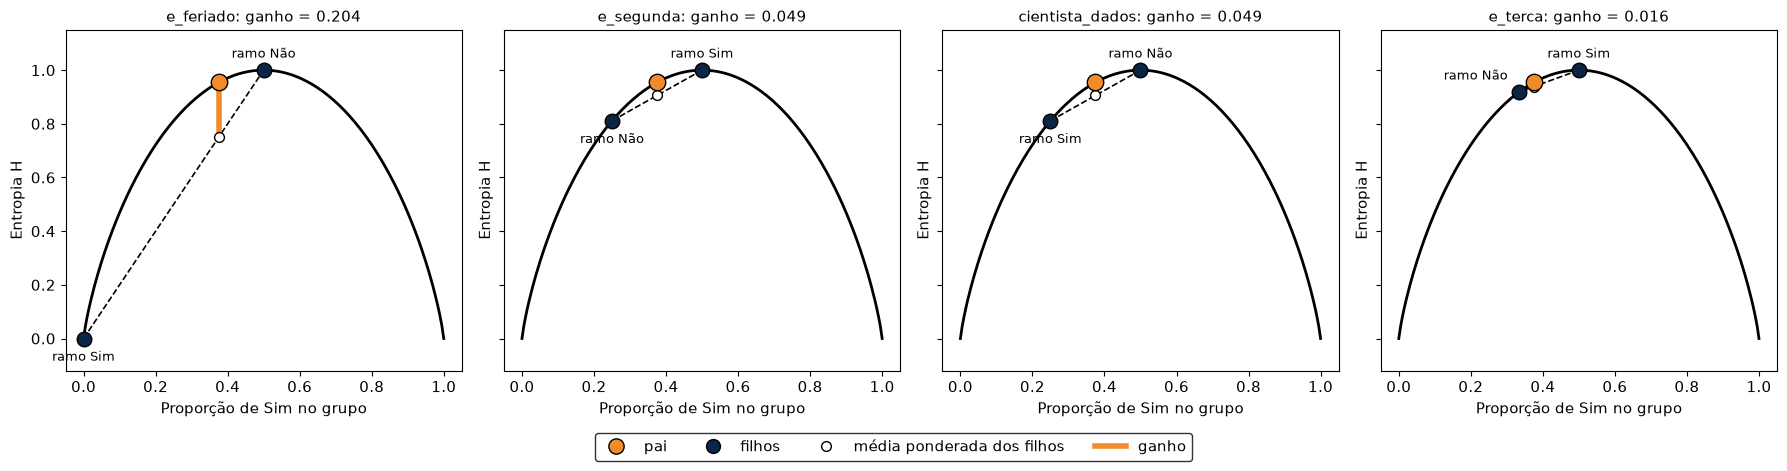

In [13]:
def curva_entropia(ax, dados, feature, alvo="presencial"):
    # Curva H(p) com o pai, os dois filhos e o ganho de uma pergunta
    p = np.linspace(0, 1, 201)
    log = lambda x, ok: np.log2(x, where=ok, out=np.zeros_like(x))
    ax.plot(p, -(p * log(p, p > 0) + (1 - p) * log(1 - p, p < 1)), color=PRETO, lw=2)

    prop_sim = lambda g: (g[alvo] == "Sim").mean()
    sim, nao = dados[dados[feature] == 1], dados[dados[feature] == 0]
    p_pai, h_pai = prop_sim(dados), entropia(dados[alvo])
    filhos = [(prop_sim(g), entropia(g[alvo]), nome) for g, nome in ((sim, "ramo Sim"), (nao, "ramo Não"))]
    h_media = (len(sim) * filhos[0][1] + len(nao) * filhos[1][1]) / len(dados)

    ax.plot([filhos[0][0], filhos[1][0]], [filhos[0][1], filhos[1][1]], color=PRETO, ls="--", lw=1.2)
    ax.vlines(p_pai, h_media, h_pai, color=LARANJA, lw=4)
    ax.scatter([p_pai], [h_media], s=50, facecolors=BRANCO, edgecolors=PRETO, zorder=3)
    for x, h, nome in filhos:
        ax.scatter([x], [h], s=110, c=AZUL_ESCURO, edgecolors=PRETO, zorder=4)
        # filho colado no pai: o rótulo vai para o lado oposto ao pai
        lado = np.sign(x - p_pai) if abs(x - p_pai) < 0.1 else 0
        ax.annotate(nome, (x, h), xytext=(lado * 8, 9 if h > 0.85 else -16), textcoords="offset points",
                    ha={-1: "right", 0: "center", 1: "left"}[int(lado)], fontsize=9)
    ax.scatter([p_pai], [h_pai], s=140, c=LARANJA, edgecolors=PRETO, zorder=5)
    ax.set_title(f"{feature}: ganho = {h_pai - h_media:.3f}", fontsize=11)
    ax.set_xlim(-0.05, 1.05); ax.set_ylim(-0.12, 1.15)
    ax.set_xlabel("Proporção de Sim no grupo"); ax.set_ylabel("Entropia H")


fig, axes = plt.subplots(1, 4, figsize=(18, 4.4), sharey=True)
for ax, f in zip(axes, FEATURES2):
    curva_entropia(ax, df2, f)
legenda = [
    plt.Line2D([], [], marker="o", ls="", markersize=11, markerfacecolor=LARANJA, markeredgecolor=PRETO, label="pai"),
    plt.Line2D([], [], marker="o", ls="", markersize=10, markerfacecolor=AZUL_ESCURO, markeredgecolor=PRETO, label="filhos"),
    plt.Line2D([], [], marker="o", ls="", markersize=7, markerfacecolor=BRANCO, markeredgecolor=PRETO, label="média ponderada dos filhos"),
    plt.Line2D([], [], color=LARANJA, lw=4, label="ganho"),
]
fig.legend(handles=legenda, loc="lower center", ncol=4, edgecolor=PRETO, bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

**Surpresa:** a intuição diria para perguntar "É feriado?" só **dentro** do ramo da segunda.
Mas o algoritmo coloca **feriado na raiz**: é a pergunta que mais limpa a mistura de uma vez.

A Árvore de Decisão é **gulosa**: escolhe a melhor pergunta **em cada passo**, não a que parece mais lógica para nós.

No ramo "não é feriado" sobram exatamente os 6 casos do exemplo base — então ali dentro cresce a mesma árvore de antes.

|--- e_feriado <= 0.50
|   |--- e_segunda <= 0.50
|   |   |--- cientista_dados <= 0.50
|   |   |   |--- e_terca <= 0.50
|   |   |   |   |--- class: Não
|   |   |   |--- e_terca >  0.50
|   |   |   |   |--- class: Sim
|   |   |--- cientista_dados >  0.50
|   |   |   |--- class: Não
|   |--- e_segunda >  0.50
|   |   |--- class: Sim
|--- e_feriado >  0.50
|   |--- class: Não



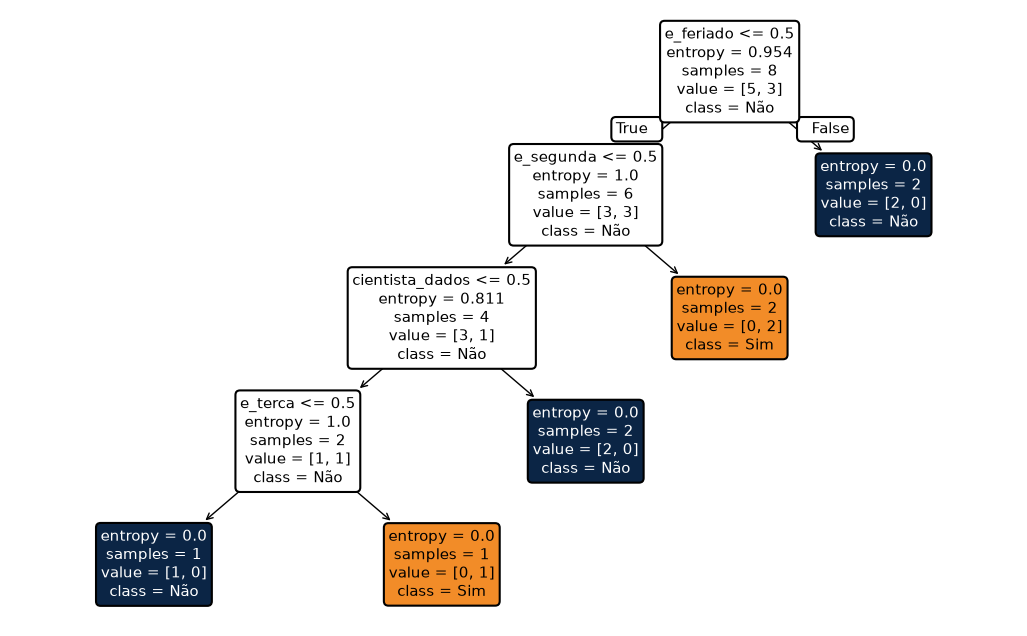

In [14]:
arvore2 = DecisionTreeClassifier(criterion="entropy", random_state=2)
arvore2.fit(df2[FEATURES2], df2["presencial"])

print(export_text(arvore2, feature_names=FEATURES2))
desenhar_arvore(arvore2, FEATURES2, tamanho=(13, 8))

## 6. Classificando um novo dado
Preencha as respostas e veja o caminho que o dado percorre na árvore final (com feriado).

In [15]:
def classificar(modelo, features, novo):
    t = modelo.tree_
    no = 0
    while t.children_left[no] != -1:
        f = features[t.feature[no]]
        valor = novo[f]
        print(f"{f}? {'Sim' if valor else 'Não'}")
        no = t.children_right[no] if valor > t.threshold[no] else t.children_left[no]
    print("Presencial?", modelo.predict(pd.DataFrame([novo])[features])[0])


# Altere os valores (1 = Sim, 0 = Não) e rode a célula de novo
novo = {"e_feriado": 0, "cientista_dados": 0, "e_segunda": 0, "e_terca": 1}
classificar(arvore2, FEATURES2, novo)

e_feriado? Não
e_segunda? Não
cientista_dados? Não
e_terca? Sim
Presencial? Sim


## 7. Pontos positivos e negativos da Árvore de Decisão (classificação)

**Pontos positivos**
- **Fácil de explicar:** o modelo vira regras Sim/Não que qualquer pessoa lê — "se é segunda, vai presencial".
- **Captura interações sozinha:** "terça" só importa para quem não é cientista; a árvore descobriu isso sem a gente dizer.
- **Seleciona variáveis:** pergunta que não ajuda não entra (terça teve ganho 0 na raiz).
- **Pouco preparo dos dados:** não precisa normalizar nem padronizar; aceita variáveis Sim/Não, categóricas e numéricas.
- **Rápida** para treinar e para prever.

**Pontos negativos**
- **Gulosa:** escolhe a melhor pergunta em cada passo, não a melhor árvore — vimos "feriado" ir para a raiz.
- **Instável:** 2 linhas novas (os feriados) mudaram a raiz inteira; empates dependem do `random_state`.
- **Overfitting:** deixada crescer até as folhas ficarem puras, ela decora os dados. Em dados reais, com ruído,
  é preciso limitar (`max_depth`, `min_samples_leaf`) ou podar.
- **Só cortes retos:** as divisões são sempre paralelas aos eixos (as "retas" do quadrante); uma fronteira diagonal vira uma escada.
- **Viés da entropia:** variáveis com muitos valores distintos (um ID, por exemplo) parecem ter ganho alto sem ter valor real.

---

# Parte 2 — Regressão: consumo de cerveja em São Paulo

**Exemplo 2** — Árvore de Regressão com Python + scikit-learn.

No exemplo 1 a árvore respondia **"qual classe?"** (Presencial Sim/Não). Agora ela responde **"quanto?"**:
quantos litros de cerveja serão consumidos em um dia.

Dataset: *Beer Consumption – São Paulo* (Kaggle) — consumo diário de cerveja em 2015, junto com o clima do dia.

Para enxergar **cada corte** da árvore num único gráfico, usamos **uma variável só**: a temperatura.

| variável | significado |
|---|---|
| `temp_max` | Temperatura máxima do dia (°C) |
| **`consumo_litros`** (alvo) | **Consumo de cerveja no dia (litros)** |

> No CSV o consumo aparece como `25.461`: o ponto é **separador de milhar**, ou seja, **25.461 litros** (cerca de 25 mil litros por dia).

Paleta: **Preto, Branco, Azul Escuro (os dias) e Laranja (a previsão da árvore)**.

In [16]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeRegressor, plot_tree, export_text
from sklearn.model_selection import train_test_split

PRETO, BRANCO, LARANJA, AZUL_ESCURO = "#000000", "#FFFFFF", "#F28C28", "#0B2545"

# formatação brasileira: 25401.4 -> "25.401"
num = lambda x: f"{x:,.0f}".replace(",", ".")
litros = lambda x: num(x) + " L"

plt.rcParams.update({
    "figure.facecolor": BRANCO, "axes.facecolor": BRANCO,
    "axes.edgecolor": PRETO, "axes.labelcolor": PRETO, "text.color": PRETO,
    "xtick.color": PRETO, "ytick.color": PRETO, "font.size": 11,
})

## 1. Dados
O CSV usa **vírgula decimal** nas temperaturas e **ponto como separador de milhar** no consumo (`25.461` = 25.461 litros).
Também traz linhas vazias no fim. Limpamos e ficamos com os 365 dias de 2015.

In [17]:
bruto = pd.read_csv("Consumo_cerveja.csv", decimal=",", thousands=".").dropna(how="all")
df_cerveja = bruto.rename(columns={
    "Temperatura Maxima (C)": "temp_max",
    "Final de Semana": "fim_de_semana",
    "Consumo de cerveja (litros)": "consumo_litros",
})[["Data", "temp_max", "fim_de_semana", "consumo_litros"]]
df_cerveja["fim_de_semana"] = df_cerveja["fim_de_semana"].astype(int)
df_cerveja["consumo_litros"] = df_cerveja["consumo_litros"].astype(float)

FEATURES_REG = ["temp_max"]
ALVO = "consumo_litros"
print(len(df_cerveja), "dias")
df_cerveja.head()

365 dias


,Data,temp_max,fim_de_semana,consumo_litros
0,2015-01-01,32.5,0,25461.0
1,2015-01-02,33.5,0,28972.0
2,2015-01-03,29.9,1,30814.0
3,2015-01-04,28.6,1,29799.0
4,2015-01-05,28.3,0,28900.0


In [18]:
df_cerveja[["temp_max", "consumo_litros"]].describe().round(1)

,temp_max,consumo_litros
count,365.0,365.0
mean,26.6,25401.4
std,4.3,4399.1
min,14.5,14343.0
25%,23.8,22008.0
50%,26.9,24867.0
75%,29.4,28631.0
max,36.5,37937.0


**Sem árvore nenhuma**, o melhor palpite para qualquer dia é a **média** do consumo.
Medimos o erro desse palpite com o **MSE** (erro quadrático médio) e o **MAE** (erro absoluto médio, em litros).

In [19]:
media = df_cerveja[ALVO].mean()
print(f"Média geral: {litros(media)}")
print(f"MSE prevendo sempre a média: {num(((df_cerveja[ALVO] - media) ** 2).mean())} (litros²)")
print(f"MAE prevendo sempre a média: {litros((df_cerveja[ALVO] - media).abs().mean())}")

Média geral: 25.401 L
MSE prevendo sempre a média: 19.299.436 (litros²)
MAE prevendo sempre a média: 3.609 L


## 2. Intuição: cortes e "degraus"
Na classificação, as retas separavam **cores**. Na regressão, cada corte é uma **linha vertical** na temperatura e a
previsão de cada faixa é a **média** do consumo ali dentro — uma linha horizontal. O resultado é uma **escada**.

1. **Sem pergunta:** uma linha só, na média geral.
2. **1º corte — temperatura máxima ≤ 25,85 °C?** Dias frios de um lado, quentes do outro, cada um com sua média.
3. **2º nível:** a mesma pergunta, agora **dentro** de cada lado. O lado frio corta em 20,7 °C e o quente em 29,25 °C → 4 degraus.

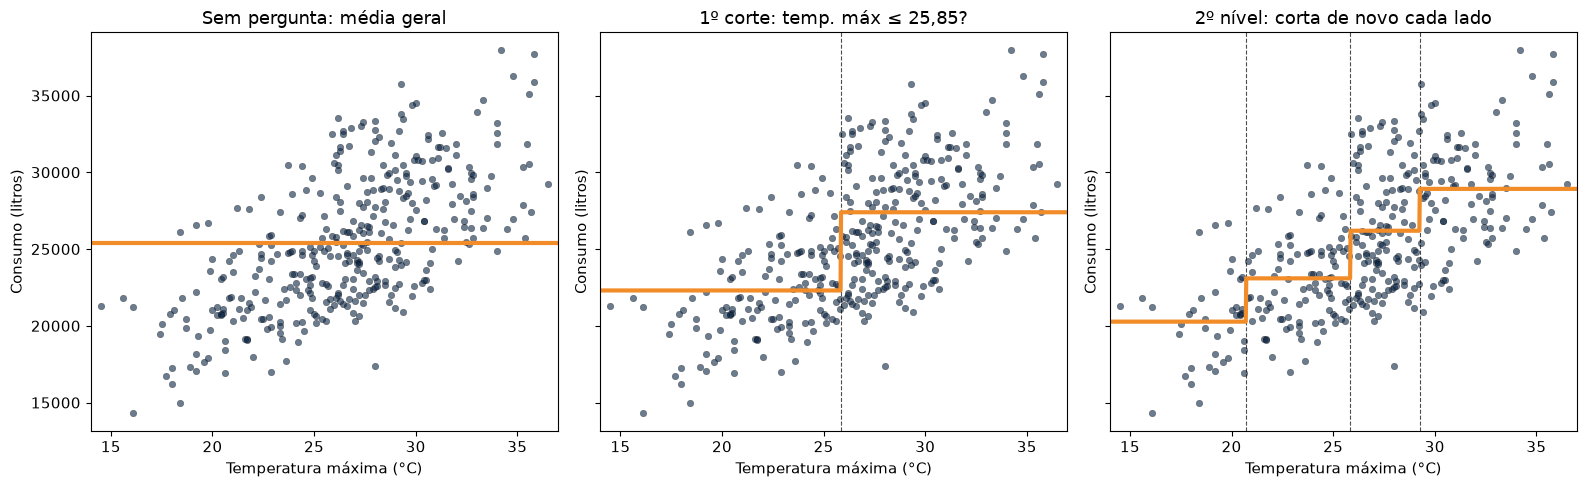

In [20]:
LIMIAR = 25.85
x_min, x_max = df_cerveja["temp_max"].min() - 0.5, df_cerveja["temp_max"].max() + 0.5
grade = pd.DataFrame({"temp_max": np.linspace(x_min, x_max, 1000)})


def arvore_temp(**params):
    return DecisionTreeRegressor(random_state=0, **params).fit(df_cerveja[FEATURES_REG], df_cerveja[ALVO])


def degraus(ax, modelo, titulo):
    # Pontos = dias; tracejado = cortes da árvore; linha laranja = previsão
    ax.scatter(df_cerveja["temp_max"], df_cerveja[ALVO], s=22, c=AZUL_ESCURO, edgecolors=PRETO,
               linewidths=0.3, alpha=0.6)
    if modelo is None:
        ax.hlines(df_cerveja[ALVO].mean(), x_min, x_max, color=LARANJA, lw=3)
    else:
        cortes = modelo.tree_.threshold[modelo.tree_.children_left != -1]
        for limiar in cortes:
            ax.axvline(limiar, color=PRETO, lw=0.8, ls="--", alpha=0.7 if len(cortes) <= 10 else 0.25)
        ax.plot(grade["temp_max"], modelo.predict(grade), color=LARANJA, lw=3)
    ax.set_xlim(x_min, x_max)
    ax.set_xlabel("Temperatura máxima (°C)"); ax.set_ylabel("Consumo (litros)")
    ax.set_title(titulo)


fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)
degraus(axes[0], None, "Sem pergunta: média geral")
degraus(axes[1], arvore_temp(max_depth=1), "1º corte: temp. máx ≤ 25,85?")
degraus(axes[2], arvore_temp(max_depth=2), "2º nível: corta de novo cada lado")
plt.tight_layout(); plt.show()

## 3. MSE e Redução do erro
Na classificação medíamos a **mistura** com a Entropia. Na regressão medimos o **espalhamento** dos valores em torno da média
com o **MSE** (é a variância do grupo):

$$MSE(S) = \frac{1}{n}\sum_{i=1}^{n} (y_i - \bar{y})^2$$

- $MSE = 0$ → todos os dias do grupo têm o mesmo consumo (grupo "puro")
- quanto maior, mais espalhado o consumo e pior a média como previsão
- a unidade é **litros²**, por isso os números são grandes; $\sqrt{MSE}$ volta para litros

O papel do Ganho de Informação passa para a **Redução do MSE**:

$$\Delta MSE = MSE(pai) - \sum_{filhos} \frac{n_{filho}}{n_{pai}}\, MSE(filho)$$

Com uma variável só, "escolher a pergunta" vira **"escolher onde cortar"**. Como `temp_max` é numérica, a árvore testa
todos os limiares possíveis (o ponto médio entre dois valores vizinhos) e fica com o de maior redução.

### Exemplo passo a passo na raiz

1. **Raiz:** 365 dias, média **25.401 L**, MSE **19.299.436** (≈ 19,3 milhões de litros²).
2. **Melhor limiar: 25,85 °C** → frio: 143 dias, média 22.303 L, MSE 9.825.960 · quente: 222 dias, média 27.397 L, MSE 15.235.459.
3. **MSE ponderado:** $\tfrac{143}{365} \times 9.825.960 + \tfrac{222}{365} \times 15.235.459 = 13.116.121$
4. **Redução:** $19.299.436 - 13.116.121 = 6.183.315$

A mesma conta em Python:

In [21]:
def mse(y):
    return float(((y - y.mean()) ** 2).mean()) if len(y) else 0.0


def reducao(dados, feature, limiar):
    esq = dados[dados[feature] <= limiar][ALVO]
    dir_ = dados[dados[feature] > limiar][ALVO]
    filhos = (len(esq) * mse(esq) + len(dir_) * mse(dir_)) / len(dados)
    return mse(dados[ALVO]) - filhos, esq, dir_


pai = df_cerveja[ALVO]
print(f"1. Raiz: {len(pai)} dias, média {litros(pai.mean())}, MSE {num(mse(pai))}")
red, esq, dir_ = reducao(df_cerveja, "temp_max", LIMIAR)
print(f"2. Corte em {LIMIAR} °C:")
for nome, g in (("frio", esq), ("quente", dir_)):
    print(f"   {nome:>6}: {len(g)} dias, média {litros(g.mean())}, MSE {num(mse(g))}")
filhos = mse(pai) - red
print(f"3. MSE ponderado = {len(esq)}/{len(pai)} × {num(mse(esq))} + {len(dir_)}/{len(pai)} × {num(mse(dir_))} = {num(filhos)}")
print(f"4. Redução = {num(mse(pai))} − {num(filhos)} = {num(red)}")

1. Raiz: 365 dias, média 25.401 L, MSE 19.299.436
2. Corte em 25.85 °C:
     frio: 143 dias, média 22.303 L, MSE 9.825.960
   quente: 222 dias, média 27.397 L, MSE 15.235.459
3. MSE ponderado = 143/365 × 9.825.960 + 222/365 × 15.235.459 = 13.116.121
4. Redução = 19.299.436 − 13.116.121 = 6.183.315


### Como a árvore escolhe o limiar da temperatura
Ela calcula a redução para **cada** limiar candidato. O pico da curva é o corte escolhido.

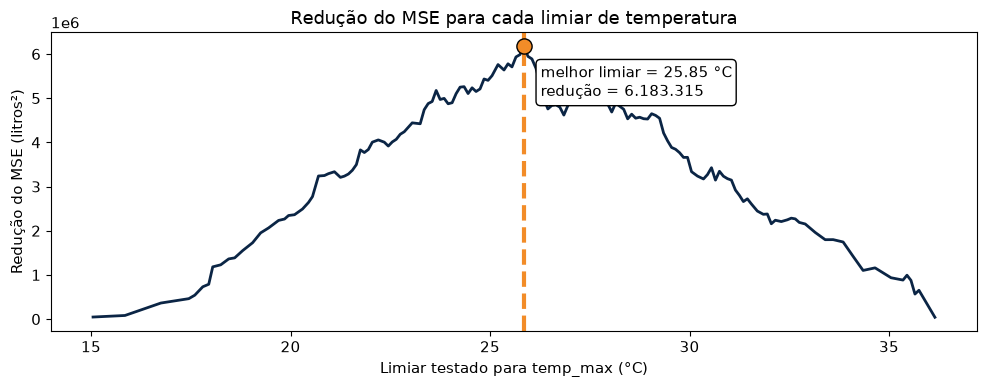

In [22]:
def melhor_corte(dados, feature="temp_max"):
    valores = np.sort(dados[feature].unique())
    limiares = (valores[:-1] + valores[1:]) / 2
    reducoes = np.array([reducao(dados, feature, t)[0] for t in limiares])
    return limiares, reducoes


def curva(ax, dados, titulo):
    limiares, reducoes = melhor_corte(dados)
    melhor = limiares[reducoes.argmax()]
    ax.plot(limiares, reducoes, color=AZUL_ESCURO, lw=2)
    ax.axvline(melhor, color=LARANJA, lw=3, ls="--")
    ax.scatter([melhor], [reducoes.max()], s=120, c=LARANJA, edgecolors=PRETO, zorder=3)
    ax.annotate(f"melhor limiar = {melhor:.2f} °C\nredução = {num(reducoes.max())}", (melhor, reducoes.max()),
                xytext=(12, -36), textcoords="offset points",
                bbox=dict(boxstyle="round", facecolor=BRANCO, edgecolor=PRETO))
    ax.set_xlabel("Limiar testado para temp_max (°C)"); ax.set_ylabel("Redução do MSE (litros²)")
    ax.set_title(titulo)
    return melhor


fig, ax = plt.subplots(figsize=(10, 4))
melhor = curva(ax, df_cerveja, "Redução do MSE para cada limiar de temperatura")
plt.tight_layout(); plt.show()

### Nível 2 — a mesma conta dentro de cada lado
Não há nada de novo no 2º nível: a árvore repete a curva acima, agora só com os dias de cada lado.

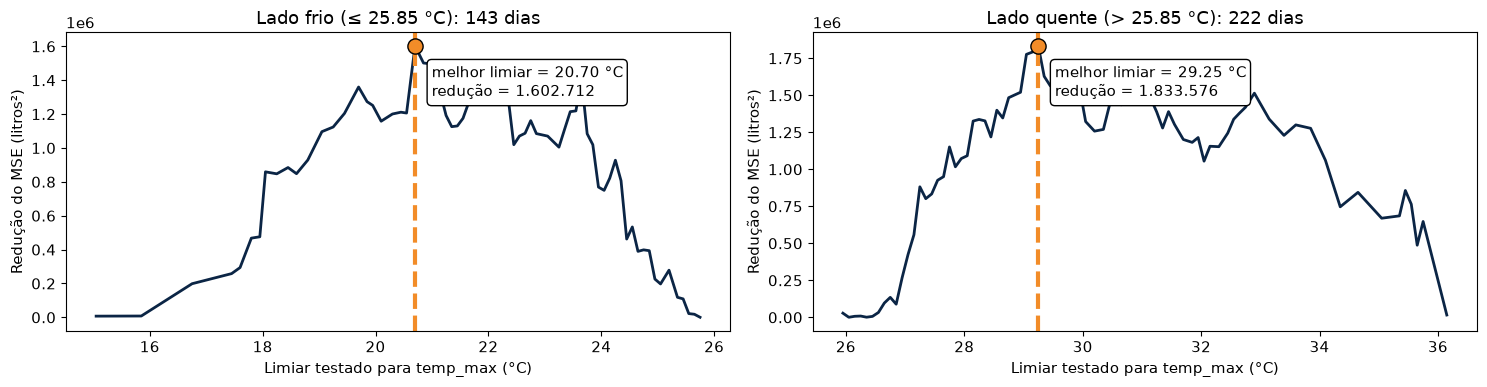

In [23]:
frio = df_cerveja[df_cerveja["temp_max"] <= melhor]
quente = df_cerveja[df_cerveja["temp_max"] > melhor]

fig, axes = plt.subplots(1, 2, figsize=(15, 4))
corte_frio = curva(axes[0], frio, f"Lado frio (≤ {melhor:.2f} °C): {len(frio)} dias")
corte_quente = curva(axes[1], quente, f"Lado quente (> {melhor:.2f} °C): {len(quente)} dias")
plt.tight_layout(); plt.show()

Os cortes de **20,70 °C** e **29,25 °C** são exatamente os do 2º painel da seção 2. A árvore poderia continuar
repetindo essa conta em cada pedaço — **até quando?** Aqui paramos em `max_depth=2`; a parte 5 mostra o que acontece se não pararmos.

## 4. A árvore com scikit-learn
`criterion="squared_error"` faz o sklearn usar exatamente a redução do MSE que calculamos.

|--- temp_max <= 25.85
|   |--- temp_max <= 20.70
|   |   |--- value: [20271.60]
|   |--- temp_max >  20.70
|   |   |--- value: [23092.03]
|--- temp_max >  25.85
|   |--- temp_max <= 29.25
|   |   |--- value: [26193.31]
|   |--- temp_max >  29.25
|   |   |--- value: [28920.27]

Cortes no sklearn: raiz 25.85 °C · frio 20.70 °C · quente 29.25 °C
Cortes manuais:    raiz 25.85 °C · frio 20.70 °C · quente 29.25 °C


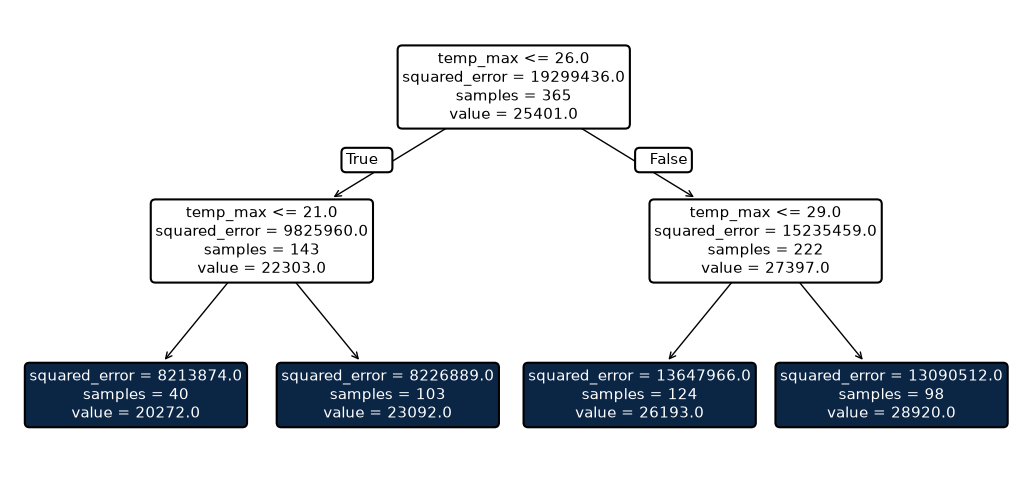

In [24]:
def desenhar_arvore_reg(modelo, features, tamanho=(13, 6)):
    fig, ax = plt.subplots(figsize=tamanho)
    nos = plot_tree(modelo, feature_names=features, filled=True, rounded=True, impurity=True,
                    precision=0, fontsize=11, ax=ax)

    # Aplica a paleta: folhas azul escuro com texto branco, nós internos brancos
    for texto in nos:
        folha = "value" in texto.get_text() and "<=" not in texto.get_text()
        texto.set_color(BRANCO if folha else PRETO)
        texto.set_bbox(dict(boxstyle="round", facecolor=AZUL_ESCURO if folha else BRANCO,
                            edgecolor=PRETO, linewidth=1.5))
        if texto.arrow_patch is not None:
            texto.arrow_patch.set_color(PRETO)
    plt.show()


arvore_reg = DecisionTreeRegressor(criterion="squared_error", max_depth=2, random_state=0)
arvore_reg.fit(df_cerveja[FEATURES_REG], df_cerveja[ALVO])

t = arvore_reg.tree_
print(export_text(arvore_reg, feature_names=FEATURES_REG, decimals=2))  # value = litros
print(f"Cortes no sklearn: raiz {t.threshold[0]:.2f} °C · frio {t.threshold[t.children_left[0]]:.2f} °C · "
      f"quente {t.threshold[t.children_right[0]]:.2f} °C")
print(f"Cortes manuais:    raiz {melhor:.2f} °C · frio {corte_frio:.2f} °C · quente {corte_quente:.2f} °C")
desenhar_arvore_reg(arvore_reg, FEATURES_REG)

> Cada caixa mostra o `squared_error` (MSE do nó), `samples` (dias) e `value` (**a média = a previsão**).
> `True` = condição verdadeira (ramo da esquerda).

In [25]:
def erros(modelo, features):
    previsto = modelo.predict(df_cerveja[features])
    return {"MAE": litros(np.abs(previsto - df_cerveja[ALVO]).mean()),
            "RMSE": litros(np.sqrt(((previsto - df_cerveja[ALVO]) ** 2).mean()))}


sem_arvore = {"MAE": litros((df_cerveja[ALVO] - media).abs().mean()),
              "RMSE": litros(np.sqrt(((df_cerveja[ALVO] - media) ** 2).mean()))}
pd.DataFrame({"só a média": sem_arvore, "árvore (2 níveis)": erros(arvore_reg, FEATURES_REG)}).T

,MAE,RMSE
só a média,3.609 L,4.393 L
árvore (2 níveis),2.734 L,3.372 L


---
## 5. Profundidade: até onde cortar?
Nada obriga a árvore a parar em 2 níveis. Sem `max_depth`, ela continua cortando até cada folha ter só dias com a
**mesma temperatura**. Veja a escada a cada profundidade:

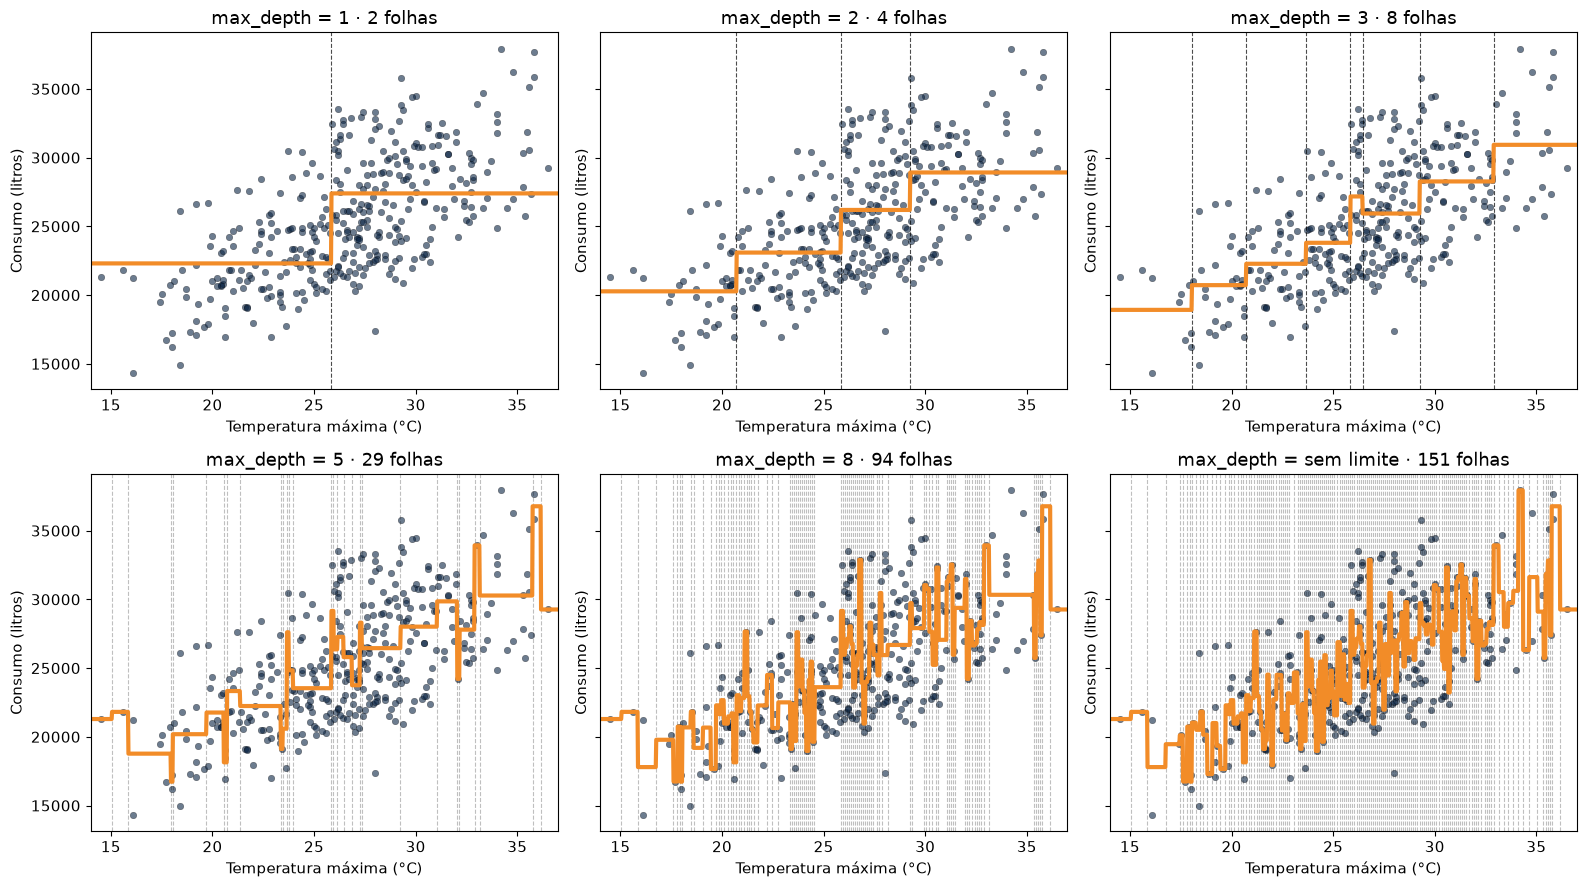

In [26]:
fig, axes = plt.subplots(2, 3, figsize=(16, 9), sharey=True)
for ax, prof in zip(axes.ravel(), [1, 2, 3, 5, 8, None]):
    modelo = arvore_temp(max_depth=prof)
    degraus(ax, modelo, f"max_depth = {prof or 'sem limite'} · {modelo.get_n_leaves()} folhas")
plt.tight_layout(); plt.show()

Com 2 ou 3 níveis a escada **sobe com a temperatura**, como esperado. A partir de 5 aparecem degraus que sobem e
descem sem motivo, e sem limite a linha persegue cada ponto: a árvore **decorou** os dias de 2015.

Só olhando o gráfico não dá para saber qual profundidade é a melhor. Para isso separamos dias que a árvore **não vê** no treino.

### Treino × teste
Separamos **75%** dos dias para treinar e **25%** para testar, e medimos o RMSE (erro típico, em litros) nos dois grupos.

> Aqui os dias de teste são sorteados entre todos os meses — basta para ensinar. Numa previsão real o teste seria
> feito com meses que vieram **depois** do treino.

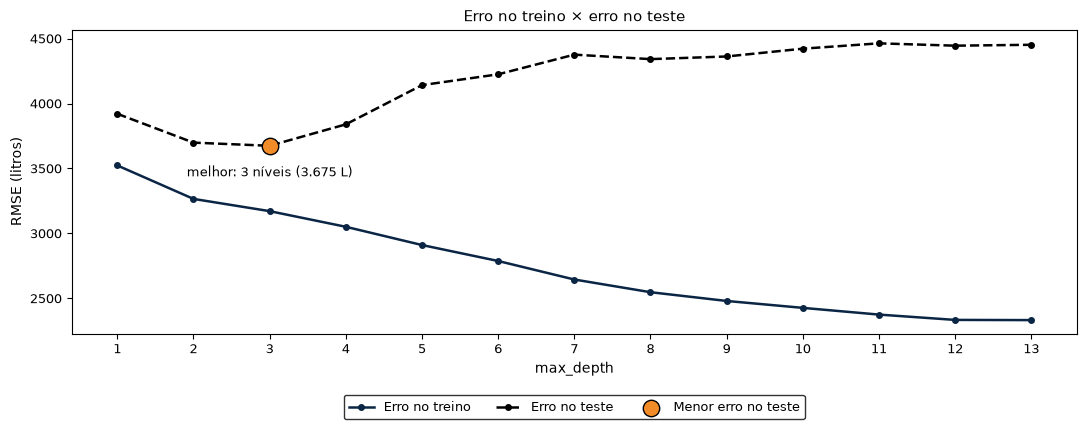

,folhas,RMSE treino,RMSE teste
max_depth,,,
1,2,3.523 L,3.921 L
2,4,3.266 L,3.699 L
3,8,3.172 L,3.675 L
4,16,3.051 L,3.840 L
5,30,2.911 L,4.142 L
6,49,2.788 L,4.225 L
7,72,2.645 L,4.376 L
8,91,2.548 L,4.342 L
9,105,2.480 L,4.362 L


In [27]:
treino, teste = train_test_split(df_cerveja, test_size=0.25, random_state=42)


def rmse(modelo, dados, features=FEATURES_REG):
    return np.sqrt(((modelo.predict(dados[features]) - dados[ALVO]) ** 2).mean())


linhas = []
for prof in range(1, 14):  # a partir de 13 a árvore já cresceu tudo
    m = DecisionTreeRegressor(max_depth=prof, random_state=0).fit(treino[FEATURES_REG], treino[ALVO])
    linhas.append({"max_depth": prof, "folhas": m.get_n_leaves(), "RMSE treino": rmse(m, treino), "RMSE teste": rmse(m, teste)})
curva_prof = pd.DataFrame(linhas)
ideal = curva_prof.loc[curva_prof["RMSE teste"].idxmin()]

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(curva_prof["max_depth"], curva_prof["RMSE treino"], color=AZUL_ESCURO, lw=1.8, marker="o", ms=4, label="Erro no treino")
ax.plot(curva_prof["max_depth"], curva_prof["RMSE teste"], color=PRETO, lw=1.8, marker="o", ms=4, ls="--", label="Erro no teste")
ax.scatter([ideal["max_depth"]], [ideal["RMSE teste"]], s=140, c=LARANJA, edgecolors=PRETO, zorder=3, label="Menor erro no teste")
# rótulo abaixo do ponto, no espaço vazio entre as duas curvas
ax.annotate(f"melhor: {int(ideal['max_depth'])} níveis ({litros(ideal['RMSE teste'])})", (ideal["max_depth"], ideal["RMSE teste"]),
            xytext=(0, -22), textcoords="offset points", ha="center", fontsize=9)
ax.set_xticks(curva_prof["max_depth"]); ax.tick_params(labelsize=9)
ax.set_xlabel("max_depth", fontsize=10); ax.set_ylabel("RMSE (litros)", fontsize=10)
ax.set_title("Erro no treino × erro no teste", fontsize=11)
# legenda fora da área do gráfico, para nenhum traço passar por cima
ax.legend(edgecolor=PRETO, fontsize=9, ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.18))
plt.tight_layout(); plt.show()

curva_prof.assign(**{c: curva_prof[c].map(litros) for c in ["RMSE treino", "RMSE teste"]}).set_index("max_depth")

O erro no **treino só cai**. O erro no **teste cai até 3 níveis e depois sobe**: esse é o **overfitting**. A partir
daí cada corte novo aprende o ruído de 2015, não a relação entre temperatura e consumo.

### Por que o erro de treino não chega a zero?
Mesmo sem limite sobra erro no treino. São 365 dias e só 151 temperaturas diferentes: dias com a mesma temperatura
caem na mesma folha e recebem a mesma previsão. Veja os dias de 28 °C:

In [28]:
dias_28 = df_cerveja[df_cerveja["temp_max"] == 28.0][["Data", "temp_max", "fim_de_semana", ALVO]]
print(f"{df_cerveja['temp_max'].nunique()} temperaturas diferentes em {len(df_cerveja)} dias")
print(f"Consumo nos dias de 28 °C: de {litros(dias_28[ALVO].min())} a {litros(dias_28[ALVO].max())}")
dias_28

151 temperaturas diferentes em 365 dias
Consumo nos dias de 28 °C: de 17.399 L a 33.330 L


,Data,temp_max,fim_de_semana,consumo_litros
31,2015-02-01,28.0,1,32057.0
47,2015-02-17,28.0,0,17399.0
221,2015-08-10,28.0,0,23181.0
228,2015-08-17,28.0,0,22541.0
282,2015-10-10,28.0,1,33330.0
339,2015-12-06,28.0,1,32780.0
341,2015-12-08,28.0,0,27713.0


A temperatura não consegue separar esses dias. Mas repare na coluna `fim_de_semana`: os dias de 28 °C de
**fim de semana** passam todos de 32 mil litros. Outras variáveis explicariam parte dessa diferença — aqui ficamos só com a temperatura.

### Outro freio: `min_samples_leaf`
Em vez de limitar a profundidade, dá para exigir um **mínimo de dias em cada folha**:

In [29]:
linhas = []
for minimo in [1, 5, 10, 20, 30]:
    m = DecisionTreeRegressor(min_samples_leaf=minimo, random_state=0).fit(treino[FEATURES_REG], treino[ALVO])
    linhas.append({"min_samples_leaf": minimo, "folhas": m.get_n_leaves(),
                   "RMSE treino": litros(rmse(m, treino)), "RMSE teste": litros(rmse(m, teste))})
pd.DataFrame(linhas).set_index("min_samples_leaf")

,folhas,RMSE treino,RMSE teste
min_samples_leaf,,,
1,138,2.333 L,4.452 L
5,44,2.880 L,3.956 L
10,19,3.046 L,3.764 L
20,11,3.154 L,3.577 L
30,7,3.213 L,3.620 L


Com pelo menos **20 dias por folha** o erro de teste fica até menor que o do `max_depth=3`: a árvore corta mais
fundo onde há muitos dias e para onde há poucos.

---
## 6. Estimando o consumo de um novo dia
Usamos a profundidade que errou menos no teste. Preencha o dia e veja o caminho percorrido na árvore.

In [30]:
def prever(modelo, features, novo_dia):
    t = modelo.tree_
    no = 0
    while t.children_left[no] != -1:
        f = features[t.feature[no]]
        sim = novo_dia[f] <= t.threshold[no]
        print(f"{f} <= {t.threshold[no]:.2f}? {'Sim' if sim else 'Não'}")
        no = t.children_left[no] if sim else t.children_right[no]
    print(f"Consumo estimado: {litros(modelo.predict(pd.DataFrame([novo_dia])[features])[0])}")


modelo_final = arvore_temp(max_depth=int(ideal["max_depth"]))

# Altere a temperatura e rode a célula de novo
novo_dia = {"temp_max": 31.0}
prever(modelo_final, FEATURES_REG, novo_dia)

temp_max <= 25.85? Não
temp_max <= 29.25? Não
temp_max <= 32.90? Sim
Consumo estimado: 28.268 L


## 7. Pontos positivos e negativos da Árvore de Regressão

**Pontos positivos**
- **Fácil de explicar:** cada folha é a média de dias parecidos — "dia acima de 32,9 °C ≈ 30,9 mil litros".
- **Captura não linearidade** sem criar variáveis novas: a escada se ajusta onde a relação muda.
- **Escolhe o corte sozinha:** testou cerca de 150 limiares e ficou com 25,85 °C.
- **Pouco preparo dos dados:** não precisa normalizar; temperatura (°C) e Sim/Não convivem na mesma árvore.
- **Ganho rápido:** com só 3 perguntas (2 níveis), o erro médio cai de 3.609 L para 2.734 L.

**Pontos negativos**
- **Previsão em degraus:** com 2 níveis só existem 4 respostas possíveis. Um dia de 25,8 °C e outro de 25,9 °C
  recebem previsões que diferem em mais de 3 mil litros.
- **Não extrapola:** o dia mais quente de 2015 teve 36,5 °C. Um dia de 40 °C recebe a mesma previsão da última folha.
- **Overfitting:** sem limite, a árvore cria 138 folhas (64 delas com um dia só) e o erro de teste sobe de 3.675 L
  para 4.452 L. É preciso escolher `max_depth` ou `min_samples_leaf` olhando o erro de teste.
- **Instável:** o limiar de 25,85 °C pode mudar bastante com dados de outro ano.
- **Uma variável só explica parte da história:** nos dias de 28 °C o consumo foi de 17 mil a 33 mil litros.
  Mais variáveis (fim de semana) e combinações de árvores (Random Forest, Gradient Boosting) costumam errar menos.